# Proyek Klasifikasi Gambar: Fruit 360 Dataset
- **Nama:** David Santoso
- **Email:** davidsantoso7566@gmail.com
- **ID Dicoding:** davsantoso

## Import Semua Packages/Library yang Digunakan

In [23]:
!pip freeze > requirements.txt

In [2]:
!pip install -q kagglehub tensorflowjs

In [3]:
# Import Library
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import random
import shutil
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [4]:
# Cek GPU
print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data Preparation

### Data Loading

In [5]:
# Import Dataset dari Kaggle
import kagglehub

path = kagglehub.dataset_download("moltean/fruits")
print("Dataset Path:", path)

base_path = os.path.join(path, "fruits-360_100x100/fruits-360")
train_path = os.path.join(base_path, "Training")
test_path = os.path.join(base_path, "Test")

Using Colab cache for faster access to the 'fruits' dataset.
Dataset Path: /kaggle/input/fruits


### Data Preprocessing

#### Split Dataset

In [6]:
# Ambil 20 kelas
# Hapus folder lama jika ada
if os.path.exists("/content/train_selected"):
    shutil.rmtree("/content/train_selected")
if os.path.exists("/content/test_selected"):
    shutil.rmtree("/content/test_selected")

all_classes = os.listdir(train_path)
selected_classes = random.sample(all_classes, 20)

new_train_path = "/content/train_selected"
new_test_path = "/content/test_selected"

os.makedirs(new_train_path)
os.makedirs(new_test_path)

for cls in selected_classes:
    shutil.copytree(os.path.join(train_path, cls),
                    os.path.join(new_train_path, cls))
    shutil.copytree(os.path.join(test_path, cls),
                    os.path.join(new_test_path, cls))

train_path = new_train_path
test_path = new_test_path

print("20 Kelas Dipilih:")
print(selected_classes)

20 Kelas Dipilih:
['Apple Red 2', 'Apple Golden 3', 'Peach 6', 'Cabbage white 1', 'Mango Red 1', 'Pepper Red 1', 'Pepper 2', 'Huckleberry 1', 'Salak 1', 'Cocos 1', 'Banana Lady Finger 1', 'Apple 11', 'Peach 2', 'Kaki 1', 'Nectarine Flat 2', 'Pear 8', 'Limes 1', 'Cucumber 8', 'Cherry Wax Red 2', 'Apple 22']


In [7]:
# Melakukan Perhitungan Gambar data
def count_images(directory):
    total = 0
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.lower().endswith(('.png','.jpg','.jpeg')):
                total += 1
    return total

train_total = count_images(train_path)
test_total = count_images(test_path)

print("Total Training Images :", train_total)
print("Total Test Images     :", test_total)
print("Total Dataset         :", train_total + test_total)

Total Training Images : 10481
Total Test Images     : 3493
Total Dataset         : 13974


In [8]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(100,100),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(100,100),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(100,100),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)
print("Jumlah Kelas:", num_classes)

Found 8390 images belonging to 20 classes.
Found 2091 images belonging to 20 classes.
Found 3493 images belonging to 20 classes.
Jumlah Kelas: 20


## Modelling

In [9]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(100,100,3)),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 98, 98, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 47, 47, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         5,140 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,375,828 (12.88 MB)

 Trainable params: 3,375,636 (12.88 MB)

 Non-trainable params: 192 (768.00 B)

In [10]:
# Training menggunakan Callback
early_stop = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint("best_model.keras", save_best_only=True, monitor='val_accuracy')
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    callbacks=[early_stop, checkpoint, reduce_lr]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 50s 161ms/step - accuracy: 0.5757 - loss: 1.9132 - val_accuracy: 0.0937 - val_loss: 8.9572 - learning_rate: 0.0010
Epoch 2/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 37s 141ms/step - accuracy: 0.9195 - loss: 0.2461 - val_accuracy: 0.9015 - val_loss: 0.3017 - learning_rate: 0.0010
Epoch 3/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 37s 140ms/step - accuracy: 0.9472 - loss: 0.1703 - val_accuracy: 0.9923 - val_loss: 0.0359 - learning_rate: 0.0010
Epoch 4/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 37s 139ms/step - accuracy: 0.9482 - loss: 0.1687 - val_accuracy: 0.9374 - val_loss: 0.1940 - learning_rate: 0.0010
Epoch 5/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 35s 134ms/step - accuracy: 0.9770 - loss: 0.0686 - val_accuracy: 0.9986 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 6/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 36s 139ms/step - accuracy: 0.9785 - loss: 0.0634 - val_accuracy: 0.9990 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 7/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 36s 138ms/step - accuracy: 0.9

## Evaluasi dan Visualisasi

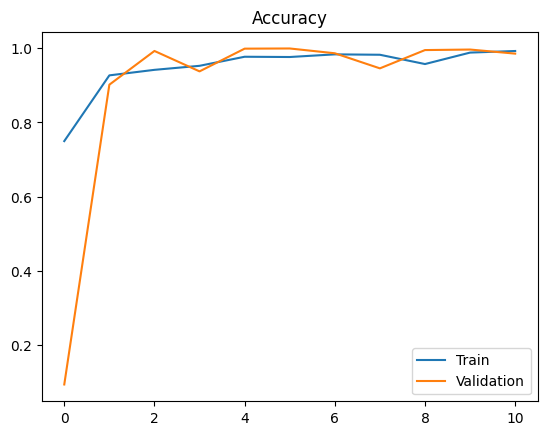

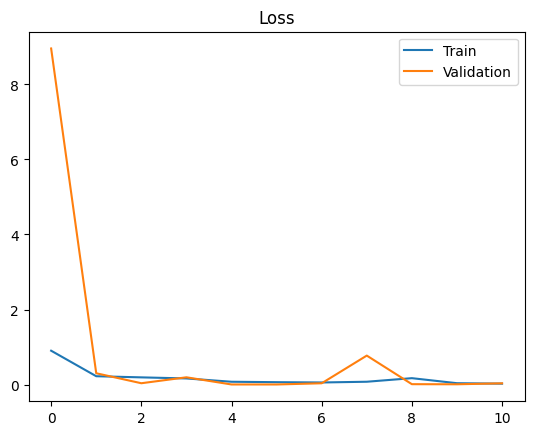

In [11]:
# Plot Akurasi & Lost
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")
plt.legend(["Train","Validation"])
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.legend(["Train","Validation"])
plt.show()

In [12]:
test_generator.reset()
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)

print(classification_report(test_generator.classes, y_pred))

110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       142
           1       1.00      1.00      1.00       231
           2       1.00      1.00      1.00       161
           3       1.00      1.00      1.00       164
           4       1.00      1.00      1.00       152
           5       1.00      1.00      1.00        47
           6       1.00      1.00      1.00       150
           7       1.00      1.00      1.00       166
           8       1.00      1.00      1.00       231
           9       1.00      1.00      1.00       166
          10       1.00      1.00      1.00       166
          11       1.00      1.00      1.00       166
          12       1.00      1.00      1.00       142
          13       1.00      1.00      1.00       153
          14       1.00      1.00      1.00       246
          15       1.00      1.00      1.00       237
          16       1.00      1.00      

In [13]:
# Test Akurasi
test_loss, test_acc = model.evaluate(test_generator)
print("Test Accuracy:", test_acc)

110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 1.0000 - loss: 9.5417e-04
Test Accuracy: 1.0


## Konversi Model

In [15]:
# SavedModel
model.export("saved_model_fruits") # Simpan SavedModel
model.save("model.keras") # Simpan format Keras

Saved artifact at 'saved_model_fruits'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 100, 100, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 20), dtype=tf.float32, name=None)
Captures:
  136824954601744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954602512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954604432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954602128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954601936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954603472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954604624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954605008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954606160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136824954606352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13682495460

In [16]:
# TF-Lite
converter = tf.lite.TFLiteConverter.from_saved_model("saved_model_fruits")
tflite_model = converter.convert()

with open("fruits_model.tflite", "wb") as f:
    f.write(tflite_model)

In [17]:
# TFJS
!tensorflowjs_converter --input_format=tf_saved_model saved_model_fruits tfjs_model

2026-02-26 08:51:37.645158: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772095897.681220   13217 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772095897.692136   13217 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772095897.719533   13217 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772095897.719573   13217 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772095897.719581   13217 computation_placer.cc:177] computation placer alr

In [26]:
# Mendownload Model
from google.colab import files
!zip -r submission_models.zip saved_model_fruits tfjs_model fruits_model.tflite model.keras requirements.txt
files.download("submission_models.zip")

  adding: saved_model_fruits/ (stored 0%)
  adding: saved_model_fruits/variables/ (stored 0%)
  adding: saved_model_fruits/variables/variables.data-00000-of-00001 (deflated 8%)
  adding: saved_model_fruits/variables/variables.index (deflated 67%)
  adding: saved_model_fruits/assets/ (stored 0%)
  adding: saved_model_fruits/fingerprint.pb (stored 0%)
  adding: saved_model_fruits/saved_model.pb (deflated 87%)
  adding: tfjs_model/ (stored 0%)
  adding: tfjs_model/group1-shard4of4.bin (deflated 8%)
  adding: tfjs_model/group1-shard2of4.bin (deflated 8%)
  adding: tfjs_model/group1-shard3of4.bin (deflated 8%)
  adding: tfjs_model/group1-shard1of4.bin (deflated 8%)
  adding: tfjs_model/model.json (deflated 90%)
  adding: fruits_model.tflite (deflated 8%)
  adding: model.keras (deflated 23%)
  adding: requirements.txt (deflated 58%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Inference (Optional)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


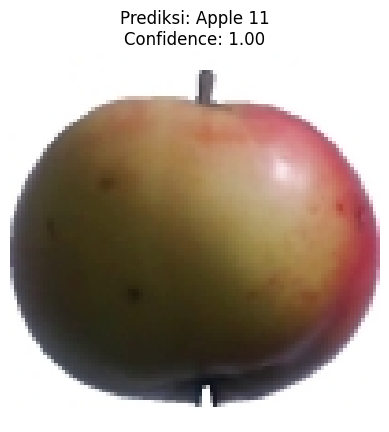

In [21]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Load model dari SavedModel
loaded_model = tf.keras.models.load_model("model.keras")

# Ambil 1 gambar dari test set
img_path = test_generator.filepaths[0]

img = image.load_img(img_path, target_size=(100,100))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Prediksi
prediction = loaded_model.predict(img_array)
predicted_class = np.argmax(prediction)
confidence = np.max(prediction)

# Ambil nama kelas
class_labels = list(test_generator.class_indices.keys())
predicted_label = class_labels[predicted_class]

# Tampilkan gambar + hasil
plt.imshow(img)
plt.axis('off')
plt.title(f"Prediksi: {predicted_label}\nConfidence: {confidence:.2f}")
plt.show()